# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch

Run these commands in a terminal, inside this project's folder, before opening the notebook.

1. Check Python: `python --version` (Python 3.10 - 3.12 works)
2. Create a virtual environment: `python -m venv venv`
3. Activate it:
   - Windows (Command Prompt): `venv\Scripts\activate.bat`
   - Windows (PowerShell): `venv\Scripts\Activate.ps1`
   - macOS / Linux: `source venv/bin/activate`
4. Install packages: `pip install -r requirements-notebook.txt`
5. Start Jupyter: `jupyter notebook`  (then open this notebook)

## Introduction

##### **Definition**
A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) from a few medical attributes.

##### **Application**
Used for learning data science and understanding which medical factors are linked to heart disease. **This is a learning project, not a medical tool.**

## Input and Output

### Inputs (Features / Attributes) - only 4 selected from the 13 available

| **Input Feature/Attribute** | **Meaning** | **Possible Values** |
| --- | --- | --- |
| **Sex** | Gender of the patient | 0 = Female, 1 = Male |
| **ChestPain** | Chest pain type (`cp`) | 1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic |
| **ExerciseAngina** | Exercise induced angina (`exang`) | 0 = No, 1 = Yes |
| **Oldpeak** | ST depression induced by exercise relative to rest | Number from 0.0 to 6.2 |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | 0 = No heart disease, 1 = Heart disease present |

**Dataset:** UCI Heart Disease (Cleveland database, 303 patients). Original target `num` is 0 (no disease) to 4; values 1-4 are treated as "disease present".

**Note:** All 4 inputs are already numbers, so **no Label Encoding is used** in this project.

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction (select 4 attributes)
- Step 5: Prepare Input and Output (data is already numeric - no Label Encoding)
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Load the Saved Model
  - Step 8.4: Model Prediction
- Step 9: Execute the Feedback Phase
- Step 10: Deploy as a Public Web App (Streamlit)

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries needed to load data, train a Support Vector
Classifier, evaluate it, and display results.
"""

# Numerical computing (arrays, math operations)
import numpy as np

# Data manipulation (DataFrames, reading/writing CSV files)
import pandas as pd

# Saving and loading the trained model
import pickle

# Divide dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Support Vector Machine (SVM) model
from sklearn import svm

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Clean table output
from prettytable import PrettyTable

# Plotting (confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
Loads the raw Cleveland heart disease data (14 columns, no header row,
missing values written as "?") into a pandas DataFrame.
"""

# The 14 standard attribute names of the Cleveland dataset
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# "?" means missing value in this dataset
raw_data = pd.read_csv("processed.cleveland.data", header=None,
                       names=column_names, na_values="?")

print("\n\nRaw Heart Disease Data (first 10 rows):")
print("=======================================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(raw_data.head(10))



Raw Heart Disease Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
1. Print the attribute (column) names.
2. Show the number of instances (rows).
3. Show the distribution of the output (num: 0 = no disease, 1-4 = disease).
"""

print("\n\nAttributes in Raw Data:")
print("=======================\n")
print(raw_data.columns)

print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("=================================\n")

print("Distribution of original output (num):")
print(raw_data["num"].value_counts().sort_index())



Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Raw Data: 303

Distribution of original output (num):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data

In [4]:
"""
Purpose of this section:
-------------------------
1. Convert the output "num" (0-4) into a binary label:
   0 -> no heart disease, 1/2/3/4 -> heart disease present.
2. Check that our 4 chosen input columns have no missing values.
"""

# Binary output: 1 if num > 0 (disease present), otherwise 0
raw_data["HeartDisease"] = (raw_data["num"] > 0).astype(int)

print("Missing values in the 4 chosen attributes:")
print(raw_data[["sex", "cp", "exang", "oldpeak"]].isnull().sum())

print("\nBinary output distribution (HeartDisease):")
print(raw_data["HeartDisease"].value_counts())

Missing values in the 4 chosen attributes:
sex        0
cp         0
exang      0
oldpeak    0
dtype: int64

Binary output distribution (HeartDisease):
HeartDisease
0    164
1    139
Name: count, dtype: int64


### Step 4: Feature Extraction (select only 4 input attributes)

In [5]:
"""
Purpose of this section:
-------------------------
The assignment allows only 4 input attributes. We select:
  sex   -> Sex            (0 = Female, 1 = Male)
  cp    -> ChestPain      (1 to 4)
  exang -> ExerciseAngina (0 = No, 1 = Yes)
  oldpeak -> Oldpeak      (ST depression, a number)
and keep HeartDisease as the output (last column).
"""

sample_data = pd.DataFrame({
    "Sex":            raw_data["sex"].astype(int),
    "ChestPain":      raw_data["cp"].astype(int),
    "ExerciseAngina": raw_data["exang"].astype(int),
    "Oldpeak":        raw_data["oldpeak"],
    "HeartDisease":   raw_data["HeartDisease"],
})

sample_data.to_csv("sample-data.csv", index=False, header=True)
print("Saved: sample-data.csv")
print("\nSelected data (first 10 rows):")
print(sample_data.head(10))
print("\nShape:", sample_data.shape)

Saved: sample-data.csv

Selected data (first 10 rows):
   Sex  ChestPain  ExerciseAngina  Oldpeak  HeartDisease
0    1          1               0      2.3             0
1    1          4               1      1.5             1
2    1          4               1      2.6             1
3    1          3               0      3.5             0
4    0          2               0      1.4             0
5    1          2               0      0.8             0
6    0          4               0      3.6             1
7    0          4               1      0.6             0
8    1          4               0      1.4             1
9    1          4               1      3.1             1

Shape: (303, 5)


### Step 5: Prepare Input and Output (No Label Encoding)

The Titanic project needed Label Encoding because its attributes were text (First, Male, Southampton...).
Here every selected attribute is **already a number**, so **no Label Encoding is performed**.
We only confirm the data types below.

In [6]:
"""
Purpose of this section:
-------------------------
Confirms that all input and output columns are numeric,
so the data can go straight into the model.
"""

print("\n\nData types of the final dataset:")
print("===============================\n")
print(sample_data.dtypes)



Data types of the final dataset:

Sex                 int64
ChestPain           int64
ExerciseAngina      int64
Oldpeak           float64
HeartDisease        int64
dtype: object


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
"""
Purpose of this section:
-------------------------
Splits the dataset into Training Data (80%) and Testing Data (20%).
random_state=0 gives the same split every time.
stratify keeps the same ratio of disease / no disease in both parts.
"""

training_data, testing_data = train_test_split(
    sample_data,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data["HeartDisease"]
)

training_data.to_csv(r"training-data.csv", index=False, header=True)
testing_data.to_csv(r"testing-data.csv", index=False, header=True)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
# Input vectors (all columns except the last)
input_vector_train = training_data.iloc[:, :-1]

# Output labels (last column = HeartDisease)
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [9]:
"""
Purpose of this section:
-------------------------
Trains a Support Vector Classifier (SVC) on the training data.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [10]:
# Save the trained model so the web app can reuse it without retraining
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
input_vector_test = testing_data.iloc[:, :-1]
output_label_test = testing_data.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

In [13]:
"""
Purpose of this section:
-------------------------
Makes predictions on the testing data and saves them next to the true labels.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data["Predictions"] = model_predictions
testing_data.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions.head(15))



Predictions Returned by svc_trained_model:

     Sex  ChestPain  ExerciseAngina  Oldpeak  HeartDisease  Predictions
125    0          2               0      0.6             0            0
83     1          3               1      1.6             1            1
53     1          2               0      0.0             0            0
45     1          3               0      2.5             1            1
248    1          4               0      1.0             1            1
211    1          1               1      3.8             1            0
36     1          4               1      2.5             1            1
106    1          4               1      0.0             1            1
120    1          4               1      0.0             1            1
31     1          4               1      1.4             1            1
156    1          4               1      1.6             1            1
157    1          4               0      0.0             1            0
148    1          

#### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.84


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.79      0.94      0.86        33
   Heart Disease (1)       0.91      0.71      0.80        28

            accuracy                           0.84        61
           macro avg       0.85      0.83      0.83        61
        weighted avg       0.85      0.84      0.83        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     31                   2
Actual: Disease                         8                  20


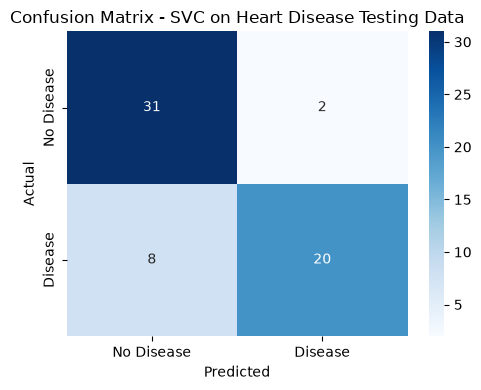

In [15]:
"""
Purpose of this section:
-------------------------
Accuracy alone can hide problems. For a medical-style task, recall matters:
of the patients who really have heart disease, how many did the model catch?
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
"""
Purpose of this section:
-------------------------
Takes the 4 input values for one patient. A demo patient is pre-filled so
the notebook runs top-to-bottom. To type your own values, replace the four
lines below with:
    sex_input = int(input("Sex (0 = Female, 1 = Male): "))
    chestpain_input = int(input("Chest pain type (1, 2, 3 or 4): "))
    exangina_input = int(input("Exercise induced angina (0 = No, 1 = Yes): "))
    oldpeak_input = float(input("Oldpeak (ST depression, e.g. 1.5): "))
"""

sex_input = 1
chestpain_input = 4
exangina_input = 1
oldpeak_input = 2.0

print(f"Sex: {sex_input}, ChestPain: {chestpain_input}, "
      f"ExerciseAngina: {exangina_input}, Oldpeak: {oldpeak_input}")

Sex: 1, ChestPain: 4, ExerciseAngina: 1, Oldpeak: 2.0

#### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [17]:
# Values are already numeric, so no encoding step is needed
unseen_data_features = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exangina_input],
    "Oldpeak": [oldpeak_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(unseen_data_features)



User Input Feature Vector:

   Sex  ChestPain  ExerciseAngina  Oldpeak
0    1          4               1      2.0


#### Step 8.3: Load the Saved Model

In [18]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))

#### Step 8.4: Model Prediction - Apply Model on the Feature Vector and Return Prediction to the User

In [19]:
predicted_value = model.predict(unseen_data_features)

if predicted_value == 1:
    prediction = "HEART DISEASE LIKELY"
else:
    prediction = "NO HEART DISEASE LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [20]:
"""
Example (illustrative) feedback table. In a real project this would come
from doctors / real users after deployment.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Doctor) - example", "Student Tester - example"],
    "Case": [
        "Male, asymptomatic chest pain, exercise angina = Yes, oldpeak 2.0 -> predicted HEART DISEASE LIKELY",
        "Female, non-anginal pain, no exercise angina, oldpeak 0.0 -> predicted NO HEART DISEASE LIKELY",
    ],
    "Feedback": [
        "Consistent with known risk patterns (asymptomatic chest pain and exercise angina are strong indicators).",
        "Reasonable, but only 4 inputs are used, so the model cannot see age, cholesterol or blood pressure.",
    ],
})
print(example_feedback.to_string(index=False))

                        Reviewer                                                                                                Case                                                                                                 Feedback
Domain Expert (Doctor) - example Male, asymptomatic chest pain, exercise angina = Yes, oldpeak 2.0 -> predicted HEART DISEASE LIKELY Consistent with known risk patterns (asymptomatic chest pain and exercise angina are strong indicators).
        Student Tester - example      Female, non-anginal pain, no exercise angina, oldpeak 0.0 -> predicted NO HEART DISEASE LIKELY      Reasonable, but only 4 inputs are used, so the model cannot see age, cholesterol or blood pressure.


#### Step 9.2: Make a List of Potential Improvements

In [21]:
improvements = [
    "Use more attributes (age, cholesterol, max heart rate, number of major vessels) instead of only 4",
    "Try other models (Logistic Regression, Random Forest) and compare accuracy",
    "Use cross-validation instead of a single train/test split for a more reliable score",
    "Optimise for recall, so fewer real heart disease cases are missed",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (age, cholesterol, max heart rate, number of major vessels) instead of only 4
2. Try other models (Logistic Regression, Random Forest) and compare accuracy
3. Use cross-validation instead of a single train/test split for a more reliable score
4. Optimise for recall, so fewer real heart disease cases are missed


#### Step 9.3: Improve the Model Based on Feedback

In [22]:
print("Next version: add more attributes, compare models with cross-validation, "
      "then replace svc_trained_model.pkl only if the new model is better.")

Next version: add more attributes, compare models with cross-validation, then replace svc_trained_model.pkl only if the new model is better.


## Step 10: Deploy Your Model as a Public Web App

1. Put these files in a **public GitHub repository**: `app.py`, `requirements.txt`, `svc_trained_model.pkl` (plus this notebook and the data files).
2. Go to **https://share.streamlit.io** and sign in with GitHub.
3. Click **Create app** -> **Deploy a public app from GitHub**.
4. Choose your repository, branch `main`, main file path `app.py`, then click **Deploy**.
5. Streamlit gives you a public link like `https://<your-app-name>.streamlit.app`.

## Conclusion
Using only 4 input attributes (Sex, ChestPain, ExerciseAngina, Oldpeak) from the UCI Cleveland heart disease dataset, a Support Vector Classifier was trained to predict whether heart disease is present. No Label Encoding was needed because all attributes are numeric. The accuracy on the held-out test set is shown in Step 7.4, with precision, recall and F1 in Step 7.5. The trained model is saved as `svc_trained_model.pkl` and deployed as a Streamlit web app. This is a learning project and must not be used for real medical decisions.